<a href="https://colab.research.google.com/github/pranawsing/DataAnalytics/blob/main/nppd1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
data_frame=pd.read_csv('/content/drive/MyDrive/insurance (1).csv')

In [5]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [6]:
data_frame['family_count']=data_frame['children']+1

In [7]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses,family_count
0,19,female,27.9,0,yes,southwest,16884.92,1
1,18,male,33.8,1,no,southeast,1725.55,2
2,28,male,33.0,3,no,southeast,4449.46,4
3,33,male,22.7,0,no,northwest,21984.47,1
4,32,male,28.9,0,no,northwest,3866.86,1


## Inplace works only on these
* data_frame.drop('age', axis=1, inplace=True)          
* data_frame.rename(columns={'age':'AGE'}, inplace=True)
* data_frame.sort_values('age', inplace=True)            
* data_frame.reset_index(inplace=True)                   



In [8]:
data_frame['avg_expence_per_child']=data_frame['expenses']/data_frame['family_count']

In [9]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child
0,19,female,27.9,0,yes,southwest,16884.92,1,16884.920
1,18,male,33.8,1,no,southeast,1725.55,2,862.775
2,28,male,33.0,3,no,southeast,4449.46,4,1112.365
3,33,male,22.7,0,no,northwest,21984.47,1,21984.470
4,32,male,28.9,0,no,northwest,3866.86,1,3866.860


* loc=specified index
* iloc= default index (integer)

In [10]:
data_frame.loc[:,['age','sex']].head()

,age,sex
0,19,female
1,18,male
2,28,male
3,33,male
4,32,male


In [11]:
data_frame.iloc[:,6].head()

,expenses
0,16884.92
1,1725.55
2,4449.46
3,21984.47
4,3866.86


In [12]:
data_frame.iloc[:, 0:2].head()  # age=col0, sex=col1

,age,sex
0,19,female
1,18,male
2,28,male
3,33,male
4,32,male


In [13]:
data_frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    1338 non-null   int64  
 1   sex                    1338 non-null   object 
 2   bmi                    1338 non-null   float64
 3   children               1338 non-null   int64  
 4   smoker                 1338 non-null   object 
 5   region                 1338 non-null   object 
 6   expenses               1338 non-null   float64
 7   family_count           1338 non-null   int64  
 8   avg_expence_per_child  1338 non-null   float64
dtypes: float64(3), int64(3), object(3)
memory usage: 94.2+ KB


## We have to define axis
* axis 1 = column
* axis 0 = rows
# If axis is not define it will search all the rows and find where is children column and throw error because there is no children in row

In [14]:
#from google.colab import sheets
#sheet = sheets.InteractiveSheet(df=data_frame2)
# for converting intractive sheet meens converting into excel

In [15]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child
0,19,female,27.9,0,yes,southwest,16884.92,1,16884.920
1,18,male,33.8,1,no,southeast,1725.55,2,862.775
2,28,male,33.0,3,no,southeast,4449.46,4,1112.365
3,33,male,22.7,0,no,northwest,21984.47,1,21984.470
4,32,male,28.9,0,no,northwest,3866.86,1,3866.860


In [16]:
df1=data_frame.groupby('age')

In [17]:
df1

In [18]:
data_frame.sort_values(['age','bmi'],inplace=True,ascending=[True,True])

In [19]:
df1.head()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child
172,18,male,16.0,0,no,northeast,1694.80,1,1694.800000
250,18,male,17.3,2,yes,northeast,12829.46,3,4276.486667
359,18,female,20.8,0,no,southeast,1607.51,1,1607.510000
1212,18,male,21.5,0,no,northeast,1702.46,1,1702.460000
1033,18,male,21.6,0,yes,northeast,13747.87,1,13747.870000
...,...,...,...,...,...,...,...,...,...
108,29,male,27.9,0,no,southeast,2867.12,1,2867.120000
671,29,female,31.2,0,no,northeast,3943.60,1,3943.600000
145,29,female,38.8,3,no,southeast,5138.26,4,1284.565000
1324,31,male,25.9,1,no,northwest,4239.89,2,2119.945000


In [20]:
df1['avg_expence_per_child'].mean().head()

,avg_expence_per_child
age,
18,9331.831486
19,9063.223782
20,8153.830747
21,4371.326702
22,10538.596875


* df1['avg_expence_per_child'].sum()     # total expenses per age
* df2.groupby('age').mean()    # average bmi per age
* df2.groupby('age').count()   # how many people per age
* df2.groupby('age').max()     # maximum expenses per age
* df2.groupby('age').min()     # minimum expenses per age

In [21]:
df1['avg_expence_per_child'].aggregate(['mean','sum','std','count','std']).head()
#number of coustomer in age gorup (count)

,mean,sum,std,count,std
age,,,,,
18,9331.831486,643896.372500,11162.765234,69,11162.765234
19,9063.223782,616299.217167,9267.522535,68,9267.522535
20,8153.830747,236461.091667,8191.063105,29,8191.063105
21,4371.326702,122397.147667,3720.076136,28,3720.076136
22,10538.596875,295080.712500,9749.604731,28,9749.604731


In [22]:
df1[['avg_expence_per_child','bmi']].aggregate(['mean','sum','std','count']).head()

avg_expence_per_child                                           bmi  \
                     mean            sum           std count       mean   
age                                                                       
18            9331.831486  643896.372500  11162.765234    69  31.759420   
19            9063.223782  616299.217167   9267.522535    68  30.454412   
20            8153.830747  236461.091667   8191.063105    29  31.751724   
21            4371.326702  122397.147667   3720.076136    28  30.439286   
22           10538.596875  295080.712500   9749.604731    28  30.471429   

                             
        sum       std count  
age                          
18   2191.4  7.290189    69  
19   2070.9  6.653008    68  
20    920.8  6.872129    29  
21    852.3  6.001255    28  
22    853.2  6.943575    28

In [23]:
def compute_age(age):
  if age<23:
    return 'young'
  elif(age>23) and (age<50):
    return 'adult'
  else:
    return 'aged'

In [24]:
data_frame['age_group']=data_frame['age'].apply(compute_age)

In [25]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child,age_group
172,18,male,16.0,0,no,northeast,1694.80,1,1694.800000,young
250,18,male,17.3,2,yes,northeast,12829.46,3,4276.486667,young
359,18,female,20.8,0,no,southeast,1607.51,1,1607.510000,young
1212,18,male,21.5,0,no,northeast,1702.46,1,1702.460000,young
1033,18,male,21.6,0,yes,northeast,13747.87,1,13747.870000,young


In [26]:
data_frame['age_group'].value_counts()

,count
age_group,
adult,703
aged,413
young,222


In [27]:
data_frame[data_frame['age_group'] == 'young']

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child,age_group
172,18,male,16.0,0,no,northeast,1694.80,1,1694.800000,young
250,18,male,17.3,2,yes,northeast,12829.46,3,4276.486667,young
359,18,female,20.8,0,no,southeast,1607.51,1,1607.510000,young
1212,18,male,21.5,0,no,northeast,1702.46,1,1702.460000,young
1033,18,male,21.6,0,yes,northeast,13747.87,1,13747.870000,young
...,...,...,...,...,...,...,...,...,...,...
1036,22,male,37.1,2,yes,southeast,37484.45,3,12494.816667,young
82,22,male,37.6,1,yes,southeast,37165.16,2,18582.580000,young
888,22,male,39.5,0,no,southwest,1682.60,1,1682.600000,young
78,22,female,39.8,0,no,northeast,2755.02,1,2755.020000,young


## Remove duplicate
* data_frame.drop_duplicate()
* data_frame.drop_duplicate(subset=['age','bmi'])

In [28]:
data_frame.isnull()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child,age_group
172,False,False,False,False,False,False,False,False,False,False
250,False,False,False,False,False,False,False,False,False,False
359,False,False,False,False,False,False,False,False,False,False
1212,False,False,False,False,False,False,False,False,False,False
1033,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
603,False,False,False,False,False,False,False,False,False,False
418,False,False,False,False,False,False,False,False,False,False
199,False,False,False,False,False,False,False,False,False,False
768,False,False,False,False,False,False,False,False,False,False


In [29]:
df_bool=data_frame.isnull()

In [30]:
df_bool.sum(axis=0)

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
expenses,0
family_count,0
avg_expence_per_child,0
age_group,0


In [31]:
df3=data_frame[data_frame['age']==19]
#data_bool=data_frame['age']==19
#data_frame.loc[data_bool,:]

In [32]:
df3

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child,age_group
410,19,male,17.5,0,no,northwest,1621.34,1,1621.340,young
232,19,female,17.8,0,no,southwest,1727.79,1,1727.790,young
1129,19,female,18.6,0,no,southwest,1728.90,1,1728.900,young
1251,19,male,19.8,0,no,southwest,1241.57,1,1241.570,young
681,19,male,20.3,0,no,southwest,1242.26,1,1242.260,young
...,...,...,...,...,...,...,...,...,...,...
263,19,male,37.0,0,yes,northwest,36219.41,1,36219.410,young
391,19,female,37.4,0,no,northwest,2138.07,1,2138.070,young
960,19,female,39.6,1,no,northwest,2730.11,2,1365.055,young
973,19,female,40.5,0,no,southwest,1759.34,1,1759.340,young


In [33]:
df3.shape

(68, 10)

In [34]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child,age_group
172,18,male,16.0,0,no,northeast,1694.80,1,1694.800000,young
250,18,male,17.3,2,yes,northeast,12829.46,3,4276.486667,young
359,18,female,20.8,0,no,southeast,1607.51,1,1607.510000,young
1212,18,male,21.5,0,no,northeast,1702.46,1,1702.460000,young
1033,18,male,21.6,0,yes,northeast,13747.87,1,13747.870000,young


In [35]:
data_frame.describe()

,age,bmi,children,expenses,family_count,avg_expence_per_child
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414,2.094918,8269.590948
std,14.049960,6.098382,1.205493,12110.011240,1.205493,9398.904288
min,18.000000,16.000000,0.000000,1121.870000,1.000000,768.000000
25%,27.000000,26.300000,0.000000,4740.287500,1.000000,2206.168000
50%,39.000000,30.400000,1.000000,9382.030000,2.000000,4317.090000
75%,51.000000,34.700000,2.000000,16639.915000,3.000000,11454.965000
max,64.000000,53.100000,5.000000,63770.430000,6.000000,63770.430000


<Axes: xlabel='bmi', ylabel='expenses'>

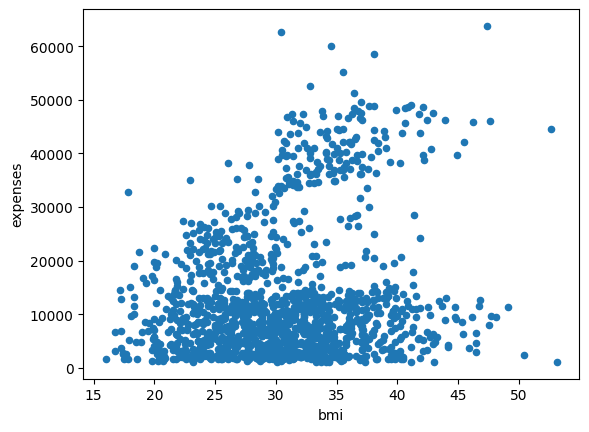

In [36]:
data_frame.plot(x='bmi',y='expenses',kind='scatter')

<Axes: ylabel='expenses'>



In [43]:
data_frame.plot(x='bmi',y='expenses',kind='pie')

In [38]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child,age_group
172,18,male,16.0,0,no,northeast,1694.80,1,1694.800000,young
250,18,male,17.3,2,yes,northeast,12829.46,3,4276.486667,young
359,18,female,20.8,0,no,southeast,1607.51,1,1607.510000,young
1212,18,male,21.5,0,no,northeast,1702.46,1,1702.460000,young
1033,18,male,21.6,0,yes,northeast,13747.87,1,13747.870000,young


In [39]:
data_frame.groupby('region')['avg_expence_per_child'].median()

,avg_expence_per_child
region,
northeast,4956.596
northwest,4011.570
southeast,4407.445
southwest,3846.140


<Axes: xlabel='region'>

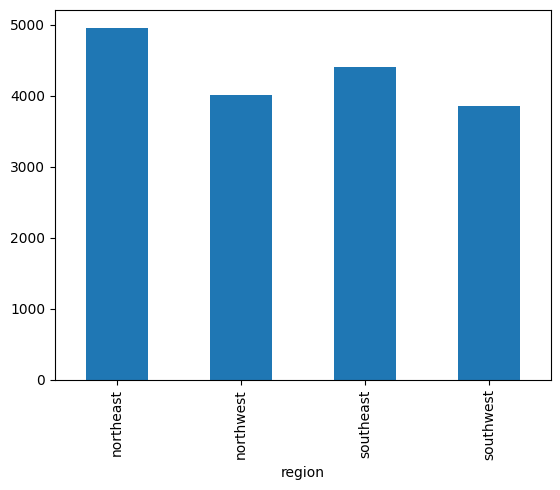

In [40]:
data_frame.groupby('region')['avg_expence_per_child'].median().plot(kind='bar')

In [41]:
data_frame.head()

,age,sex,bmi,children,smoker,region,expenses,family_count,avg_expence_per_child,age_group
172,18,male,16.0,0,no,northeast,1694.80,1,1694.800000,young
250,18,male,17.3,2,yes,northeast,12829.46,3,4276.486667,young
359,18,female,20.8,0,no,southeast,1607.51,1,1607.510000,young
1212,18,male,21.5,0,no,northeast,1702.46,1,1702.460000,young
1033,18,male,21.6,0,yes,northeast,13747.87,1,13747.870000,young




*   data_frame['expenses'] = data_frame['expenses'].astype(float)
*   data_frame['expenses'] = data_frame['expenses'].astype(int)
*   data_frame['expenses'] = data_frame['expenses'].astype(str)
*   data_frame['expenses'] = pd.to_datetime (data_frame['expenses'],format='%y'-'%m'-'%d')


## one hot/knot encoding
* pd.get_dummies(data_frame,columns=['region'])
## label encoding
* df['sex'] = df.sex.map({'male':0, 'female':1})
* map()         →  replaces text with single number (male=0, female=1)
* get_dummies() →  creates separate column for each category ✅

* region_cols = ['region_southwest','region_southeast',
               'region_northwest','region_northeast']

* data_frame['region'] = data_frame[region_cols].idxmax(axis=1).str.replace('region_','')

print(data_frame['region'])

In [42]:
s = pd.DataFrame({"region": ["southwest", "southeast", "northwest", "southeast"]})
print(pd.get_dummies(s, columns=["region"], dtype=int))

   region_northwest  region_southeast  region_southwest
0                 0                 0                 1
1                 0                 1                 0
2                 1                 0                 0
3                 0                 1                 0
